# Supplementary: egg-cap sensitivity

Tests whether Figure 3/4's finding - vitamin B12 dominates the land cost -
is an artifact of the specific per-country egg-production cap used
elsewhere, by sweeping that cap from 0.25x to 4x its baseline value and
checking whether B12's land share (and minimum B12 adequacy) stays stable.

For interactive exploration of the base model, see the companion
dashboard: **[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import functions as F
import functions_supply as FS
import global_var as GVARS

EXCLUDED_COUNTRIES = {"South Africa"}

df_composition = pd.read_csv("data/crop_composition_table.csv")
df_composition = df_composition.dropna(subset=["crop"]).set_index("crop")
df_composition = df_composition.fillna(0).replace(" ", 0).astype(float)
df_composition *= 10
df_composition["edible.prop"] /= 10

df_animal = pd.read_excel("data/animal_composition_table_with_carrying_capacity.xlsx", sheet_name="production ha-1")
df_animal = df_animal.set_index("animal").drop(columns=["fat"])

df_dri = pd.read_excel("data/food_comp_DRI.xlsx", sheet_name="dietary reference intake")
dri = (df_dri.drop(columns=["fat", "age group", "gender"]).iloc[0] * 365).values

df_yield = pd.read_csv("data/original/FAOSTAT_data_en_3-25-2026.csv")
df_yield = df_yield[["Item", "Year", "Area", "Value"]]
df_yield = df_yield.rename(columns={"Item": "crop", "Year": "year", "Area": "country", "Value": "yield_per_ha"})
df_yield["crop"] = df_yield["crop"].apply(lambda x: GVARS.mapping_FAO_to_RHOMIS.get(x, None))
duplicates_mapping = {
    "soya_bean": ["soya_bean", "broad_beans"], "peas": ["peas", "field_pea"],
    "millet": ["millet", "fingermillet", "pearl_millet"], "mango": ["mango", "guava"],
    "cabbage": ["cabbage", "kales"], "squash": ["squash", "pumpkin", "zucchini"],
    "sesame": ["sesame", "simsim"], "jackfruit": ["jackfruit", "passion_fruit"],
    "beans": ["beans", "haricot_bean", "green_gram"], "amaranth": ["amaranth", "teff"],
    "watermelon": ["watermelon", "melon"],
}
df_yield["crop"] = df_yield["crop"].apply(lambda x: duplicates_mapping.get(x, [x]))
df_yield = df_yield.explode("crop").reset_index(drop=True).dropna(subset=["crop"])
df_yield = df_yield.groupby(["country", "crop"]).agg({"yield_per_ha": "mean"}).reset_index()
df_yield = df_yield.rename(columns={"yield_per_ha": "mean"})
known_countries = pd.read_csv("data/processed/crop_yield_country.csv")["country"].unique()
df_yield = df_yield[df_yield["country"].isin(known_countries)]

heads = pd.read_csv("data/processed/all_heads_per_person_95percentiles.csv")
heads_long = heads.melt(id_vars="id_country", var_name="column", value_name="heads_per_person")
heads_long["animal"] = heads_long["column"].str.split("_").str[3]
heads_long = heads_long.drop(columns=["column"]).dropna(subset=["heads_per_person"])
heads_lookup = {(r.id_country, r.animal): r.heads_per_person for r in heads_long.itertuples()}

ANIMALS = list(GVARS.animal_lsu.keys())
countries_by_id = {k: v for k, v in GVARS.id_country_to_country_name.items() if v not in EXCLUDED_COUNTRIES}
caps0 = {c: {} for c in countries_by_id.values()}
for id_country, country in countries_by_id.items():
    macro_area = GVARS.country_to_macro_area.get(country)
    lsu_per_ha = GVARS.macro_area_to_lsu_per_ha.get(macro_area)
    if not lsu_per_ha:
        continue
    for animal in ANIMALS:
        hpp = heads_lookup.get((id_country, animal), 0.0)
        caps0[country][animal] = hpp * GVARS.animal_lsu[animal] / lsu_per_ha
for animal in ANIMALS:
    positive = [caps0[c][animal] for c in caps0 if caps0[c].get(animal, 0) > 0]
    floor = min(positive) if positive else None
    if floor is not None:
        for c in caps0:
            if caps0[c].get(animal, 0) <= 0:
                caps0[c][animal] = floor
for c in caps0:
    caps0[c]["eggs"] = caps0[c].get("chicken", 0.0)

analysed = sorted(caps0.keys())
NUTRIENT_DEFAULTS = {"ca": 2500.0, "fe": 45.0, "zn": 40.0, "vit.a": 3000.0, "vit.b3": 35.0, "vit.b6": 100.0, "vit.c": 2000.0}
yearly_ul_in_mg = {k: v * 365 for k, v in NUTRIENT_DEFAULTS.items()}
print(f"{len(analysed)} countries ready")

18 countries ready


## 2. Sweep

For each country, the cap-independent B12-supplied minimum land is
computed once; then, at each egg-cap multiplier (0.25x-4x baseline), the
full-model minimum land is recomputed with only the "eggs" cap scaled.

In [2]:
MULTIPLIERS = [0.25, 0.5, 1.0, 2.0, 4.0]

pcs, L_supp = {}, {}
for country in analysed:
    pc = F.creating_product_composition_table(
        country, df_yield, df_composition, df_animal,
        GVARS.country_to_macro_area, GVARS.macro_area_to_lsu_per_ha,
    )
    if pc is None:
        continue
    pcs[country] = pc
    supp = FS.max_mar_min_land_fixing_caloric_intakes_with_supply(
        pc, dri, yearly_ul_in_mg=yearly_ul_in_mg, land_ul_for_animals=caps0[country],
        failure="remove_constraints", supplied_nutrients=["vit.b12"])
    L_supp[country] = np.nan if supp[2] == -1 else sum(supp[1].x)

rec = []
for m in MULTIPLIERS:
    for country in pcs:
        pc, c0 = pcs[country], caps0[country]
        caps = dict(c0)
        if "eggs" in caps:
            caps["eggs"] = c0["eggs"] * m
        full = F.max_mar_min_land_fixing_caloric_intakes(
            pc, dri, yearly_ul_in_mg=yearly_ul_in_mg, land_ul_for_animals=caps, failure="remove_constraints")
        if full[2] == -1:
            continue
        x = full[1].x
        idx = {p: i for i, p in enumerate(pc.index)}
        egg_land = x[idx["eggs"]] if "eggs" in idx else np.nan
        other_anim = sum(x[idx[a]] for a in c0 if a in idx and a != "eggs")
        b12_i = list(pc.columns).index("vit.b12")
        intake = FS.from_land_to_intake(x[:len(pc)], y=False, composition=pc, edible_portion=False)
        L_full = sum(x)
        rec.append({"mult": m, "country": country, "clean": full[2] == 1, "L_full": L_full,
                    "egg_land": egg_land, "other_animal_land": other_anim,
                    "b12_nar": min(intake[b12_i] / dri[b12_i], 1.0),
                    "b12_share_%": 100 * (L_full - L_supp[country]) / L_full})
    print(f"  done {m}x")

df_s = pd.DataFrame(rec)
summ = (df_s.groupby("mult")
        .agg(total_land=("L_full", "mean"), egg_land=("egg_land", "mean"),
             other_animal_land=("other_animal_land", "mean"),
             b12_share=("b12_share_%", "mean"), b12_share_min=("b12_share_%", "min"),
             b12_share_max=("b12_share_%", "max"), b12_nar_min=("b12_nar", "min"),
             n=("clean", "size")).round(4))
print("\nEgg-cap sensitivity (South Africa excluded):")
print(summ.to_string())

base, top = summ.loc[1.0, "total_land"], summ.loc[max(MULTIPLIERS), "total_land"]
print(f"\nTotal land falls {100*(base-top)/base:.1f}% from 1x to {max(MULTIPLIERS)}x egg cap")
print(f"Egg land rises {summ.loc[1.0,'egg_land']:.3f} -> {summ.loc[max(MULTIPLIERS),'egg_land']:.3f} ha")
print(f"Non-egg animal land falls {summ.loc[1.0,'other_animal_land']:.3f} -> {summ.loc[max(MULTIPLIERS),'other_animal_land']:.3f} ha")
print(f"B12 share stays {summ['b12_share'].min():.1f}-{summ['b12_share'].max():.1f}% across the whole range; minimum B12 NAR = {df_s['b12_nar'].min():.3f}")

  done 0.25x
  done 0.5x


  done 1.0x
  done 2.0x


  done 4.0x

Egg-cap sensitivity (South Africa excluded):
      total_land  egg_land  other_animal_land  b12_share  b12_share_min  b12_share_max  b12_nar_min   n
mult                                                                                                   
0.25      0.5524     0.026             0.4256    77.5645        63.3799        86.1912          1.0  18
0.50      0.5485     0.052             0.3966    77.3748        61.9485        86.0153          1.0  18
1.00      0.5425     0.096             0.3477    77.1206        60.9844        85.8478          1.0  18
2.00      0.5328     0.171             0.2643    76.7348        60.9844        85.6797          1.0  18
4.00      0.5232     0.244             0.1831    76.3223        60.9844        85.3341          1.0  18

Total land falls 3.6% from 1x to 4.0x egg cap
Egg land rises 0.096 -> 0.244 ha
Non-egg animal land falls 0.348 -> 0.183 ha
B12 share stays 76.3-77.6% across the whole range; minimum B12 NAR = 1.000


## 3. Supplementary figure

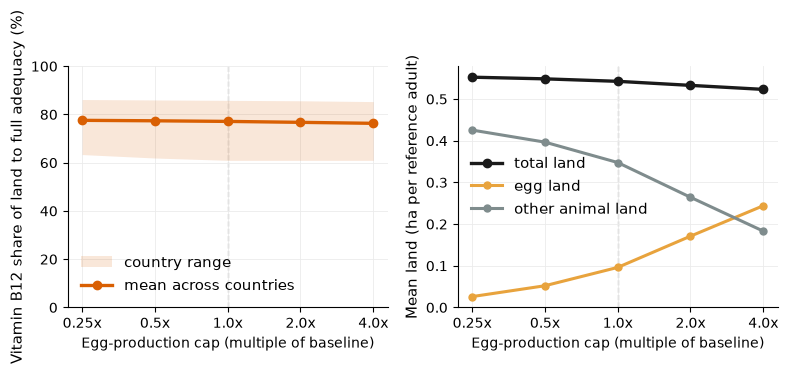

In [3]:
C_B12, C_EGG, C_OTH, C_TOT = "#d95f02", "#e8a33d", "#7f8c8d", "#1a1a1a"
mult = sorted(df_s["mult"].unique())
g = df_s.groupby("mult")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.2))
fig.set_facecolor("white")
for ax in (ax1, ax2):
    ax.set_facecolor("white")
    ax.set_xscale("log", base=2)
    ax.set_xticks(mult)
    ax.set_xticklabels([f"{m}x" for m in mult])
    ax.axvline(1.0, color="0.75", ls="--", lw=1, zorder=0)
    ax.grid(True, color="0.92", lw=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.set_xlabel("Egg-production cap (multiple of baseline)")

mean = [g.get_group(m)["b12_share_%"].mean() for m in mult]
lo = [g.get_group(m)["b12_share_%"].min() for m in mult]
hi = [g.get_group(m)["b12_share_%"].max() for m in mult]
ax1.fill_between(mult, lo, hi, color=C_B12, alpha=0.15, linewidth=0, label="country range")
ax1.plot(mult, mean, "-o", color=C_B12, lw=2.4, ms=6, label="mean across countries")
ax1.set_ylim(0, 100)
ax1.set_ylabel("Vitamin B12 share of land to full adequacy (%)", fontsize=11)
ax1.legend(frameon=False, fontsize=11, loc="lower left")

ax2.plot(mult, [g.get_group(m)["L_full"].mean() for m in mult], "-o", color=C_TOT, lw=2.4, ms=6, label="total land")
ax2.plot(mult, [g.get_group(m)["egg_land"].mean() for m in mult], "-o", color=C_EGG, lw=2.2, ms=5, label="egg land")
ax2.plot(mult, [g.get_group(m)["other_animal_land"].mean() for m in mult], "-o", color=C_OTH, lw=2.2, ms=5, label="other animal land")
ax2.set_ylim(bottom=0)
ax2.set_ylabel("Mean land (ha per reference adult)", fontsize=11)
ax2.legend(frameon=False, fontsize=11, loc="center left")

fig.tight_layout()
plt.show()

## Notes

For interactive exploration of the base model, see the companion
dashboard: **[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**
